# Unified model (for dispersing facilities from clients)
This model is a formulation for the **Obnoxious $p$-Median Problem**, specifically the "unified model" for dispersing facilities from clients, as discussed in the paper. The goal is to locate $p$ facilities such that they are as "far" as possible from clients. Unlike traditional median problems that minimize distances, obnoxious facility location maximizes them (or a proxy for them).

$$
\begin{align}
\max \quad & Kt - \sum_{i \in I} u_i \\
\text{s.t.} \quad & t - u_i \leq q_i, \quad \forall i \in I \\
& q_i = Ls_i - \sum_{j \in J} z(i,j), \quad \forall i \in I \\
& s_i - z(i,j) \leq d(i,j) + M(1-y_i), \quad \forall i \in I, j \in J \\
& \sum_{j \in J} y_j = p, \\
& u_i, z(i,j) \geq 0, y_j \in {0,1}, \forall i \in I, j \in J
\end{align}
$$

Here's a breakdown of each part:

**Sets:**
- **$I = \{1, \ldots, n\}$ (Clients):** a set of all demand points or clients that need to be "served" by the facilities.
- **$J = \{1, \ldots, m\}$ (Potential Facility Sites):** a set of all possible locations where a facility can be built.

**Parameters:**
- **$d(i,j)$:** the "distance" or undesirability measure between client $i$ and potential facility site $j$. In obnoxious location, $d(i,j)$ might represent an undesirable impact (e.g., pollution, noise), and larger values are worse for the client.
- **$K$:** a parameter in the objective function. It's related to how many of the "worst" (largest undesirable impact) client-facility assignments are considered.
- **$L$:** a parameter used in constraint (3). It relates to considering the $L$-th smallest distance (or $L$ closest facilities) for each client. In the context of maximizing dispersion, this helps in ensuring facilities are far away.
- **$p$:** the exact number of facilities to be opened.
- **$M$:** a very large positive number (often called a "Big M"). It's used in logical constraints to "turn off" parts of a constraint if a binary variable is zero. $M$ must be large enough to not restrict $s_i - z(i,j)$ when $y_j$ is $0$.

**Decision Variables:**
- **$y_j$ (Binary):** This is the core decision variable.
    - **$y_j = 1$** if a facility is opened at site $j$.
    - **$y_j = 0$** otherwise.
- **$t$ (Continuous):** an auxiliary variable introduced to help linearize the objective function. In this specific formulation, it represents a threshold related to the $K$-th smallest sum of distances, contributing to the maximization of overall dispersion.
- **$u_i$ (Continuous, Non-negative):** auxiliary variables associated with each client $i$. These variables work with $t$ in the objective and constraints to capture the idea of minimizing "undesirable impact."
- **$q_i$ (Continuous):** an auxiliary variable that connects $t$, $u_i$, $s_i$, and $z(i,j)$.
- **$s_i$ (Continuous):** an auxiliary variable for each client $i$. $s_i$ is designed to take the value of the $L$-th smallest distance from client $i$ to any opened facility.
- **$z(i,j)$ (Continuous, Non-negative):** an auxiliary variable. It becomes non-zero if facility $j$ is one of the $L$ closest facilities to client $i$ when facilities are opened.

**Objective Function:**
$$
\begin{align}
\max \quad & Kt - \sum_{i \in I} u_i
\end{align}
$$

The objective is to maximize $K$ times $t$ minus the sum of $u_i$. This structure is common in models that aim to maximize some "worst-case" scenario or dispersion. By maximizing $t$, we are trying to ensure that the $K$-th smallest values (implied by the constraints involving $t$ and $u_i$) are as large as possible, thereby maximizing the "undesirability" for the clients.

**Constraints:**
- constraint (2): **Objective Linkage Constraint** 
$$
t - u_i \leq q_i, \quad \forall i \in I
$$
These constraints link the auxiliary variable $t$ with $u_i$ and $q_i$. They are part of the linearization technique that allows the model to handle the min/max relationships effectively and define $t$ as the $K$-th smallest value related to the sums of distances.
- constraint (3): **L-th Smallest Distance Definition Constraint**
$$
q_i = Ls_i - \sum_{j \in J} z(i,j), \quad \forall i \in I
$$
This constraint relates $q_i$ to $s_i$ and $z(i,j)$. This is key for $s_i$ to represent the $L$-th smallest distance to an opened facility for client $i$.
- constraint (4): **Facility-Client Assignment Logic (Big M) Constrant**
$$
s_i - z(i,j) \leq d(i,j) + M(1-y_j), \quad \forall i \in I, j \in J
$$
This is a "Big M" constraint.
    - If $y_j = 1$ (facility $j$ is open), then $1-y_j = 0$, and the constraint becomes $s_i - z(i,j) \leq d(i,j)$. This forces $s_i$ and $z(i,j)$ to be related to the actual distance $d(i,j)$.
    - If $y_j = 0$ (facility j is not open), then $1-y_j = 1$, and the constraint becomes $s_i - z(i,j) \leq d(i,j) + M$. Since $M$ is very large, this constraint becomes effectively inactive for non-open facilities, allowing $z(i,j)$ to be $0$ (as it should be if the facility isn't open).
- constraint (5): **Cardinality Constraint** or **Number of Facilities Constraint**
$$
\sum_{j \in J} y_j = p
$$
This ensures that exactly $p$ facilities are selected and opened.

## 1. Toy model
Let's create a toy model and walk through it step-by-step.

For our toy model, let's assume:
- **Clients ($I$):** $3$ clients, indexed ${1, 2, 3}$
- **Potential Facility Sites ($J$):** $2$ potential sites, indexed ${1, 2}$
- **Number of Facilities to Open ($p$):** $1$ facility
- **$K$ (Parameter for Objective):** $3$
- **$L$ (Parameter for Constraint):** $1$
- **Distances $d(i,j)$:**
    - $d(1,1) = 10$, $d(1,2) = 5$
    - $d(2,1) = 3$, $d(2,2) = 8$
    - $d(3,1) = 7$, $d(3,2) = 12$

In [1]:
import gurobipy as gp
from gurobipy import GRB

# Set of clients I
I = [1, 2, 3]  # 3 clients
n = len(I)

# Set of potential facility sites J
J = [1, 2]   # 2 potential sites
m = len(J)

# Parameters
K = n  # Parameter K for the objective, equal to n when the unified model acts exactly as the OpMP model
L = 1  # Parameter L for constraint (3), equal to 1 when the unified model acts exactly as the OpMP model

p = 1  # Number of facilities to open (Constraint (5))

# Distance d(i,j) between client i and facility j
d = {
    (1, 1): 10, (1, 2): 5,
    (2, 1): 3,  (2, 2): 8,
    (3, 1): 7,  (3, 2): 12
}

# A large enough positive number M
# M should be greater than or equal to the maximum possible distance d(i,j).
# For the toy model, max_d is 12, so M=100 is sufficient.
M = 100

In order to plot the clients and the facilities in a graph, I then define a custom function that randomly assigns the 2D coordinates

In [2]:
import networkx as nx
import random

def build_bipartite_graph(n, m, d, x_range=(0, 100), y_range=(0, 100)):
    
    G = nx.Graph()
    
    # Add client nodes, type='client'
    for i in range(1, n+1):
        G.add_node(f"C{i}", type='client')
    
    # Add facility nodes, type='facility'
    for j in range(1, m+1):
        G.add_node(f"F{j}", type='facility')
    
    # Add edges between clients and facilities with distance attribute
    for (i, j), dist in d.items():
        G.add_edge(f"C{i}", f"F{j}", cost=dist)
    
    # Generate positions for plotting:
    # Clients on y=1 line, spaced by x
    client_pos = {f"C{i}": (generate_random_number(x_range), generate_random_number(y_range)) for i in range(1, n+1)}
    # Facilities on y=0 line, spaced by x
    facility_pos = {f"F{j}": (generate_random_number(x_range), generate_random_number(y_range)) for j in range(1, m+1)}
    pos = {**client_pos, **facility_pos}
    
    # Set position as node attributes
    nx.set_node_attributes(G, pos, 'pos')
    
    return G

def generate_random_number(range, round_to=2):
    return round(random.uniform(*range), round_to)

the I call it to generate the coordinates

In [3]:
# Build the graph
G = build_bipartite_graph(n, m, d)

In [4]:
G.nodes.data()

NodeDataView({'C1': {'type': 'client', 'pos': (74.25, 39.67)}, 'C2': {'type': 'client', 'pos': (33.46, 98.82)}, 'C3': {'type': 'client', 'pos': (45.72, 19.75)}, 'F1': {'type': 'facility', 'pos': (17.51, 8.6)}, 'F2': {'type': 'facility', 'pos': (39.58, 61.38)}})

In [5]:
G.edges.data()

EdgeDataView([('C1', 'F1', {'cost': 10}), ('C1', 'F2', {'cost': 5}), ('C2', 'F1', {'cost': 3}), ('C2', 'F2', {'cost': 8}), ('C3', 'F1', {'cost': 7}), ('C3', 'F2', {'cost': 12})])

Now, I define the function that plots the graph of the clients and the facilities with their corresponding distances

In [6]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.patches as mpatches

def draw_initial_opmpum_graph(G):

    client_nodes = [n for n, attr in G.nodes(data=True) if attr.get('type') == 'client']
    facility_nodes = [n for n, attr in G.nodes(data=True) if attr.get('type') == 'facility']

    pos = nx.get_node_attributes(G, 'pos')
    
    plt.figure(figsize=(12, 10))
    
    # Draw clients
    nx.draw_networkx_nodes(G, pos,
                           nodelist=client_nodes,
                           node_color='lightblue',
                           node_shape='o',
                           node_size=500,
                           edgecolors='black',
                           label='Clients')
    
    # Draw facilities
    nx.draw_networkx_nodes(G, pos,
                           nodelist=facility_nodes,
                           node_color='gray',
                           node_shape='s',
                           node_size=700,
                           edgecolors='black',
                           label='Facilities')
    
    # Labels with client/facility prefixes
    labels = {node: node for node in G.nodes()}
    nx.draw_networkx_labels(G, pos, labels=labels, font_color='black', font_size=10)
    
    # Draw edges
    nx.draw_networkx_edges(G, pos, alpha=0.6)
    
    # Edge labels with costs
    edge_labels = {(u, v): G.edges[u, v]['cost'] for u, v in G.edges()}
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_color='red', font_size=9)
    
    plt.title("Client-Facility Bipartite Graph with Distances")
    plt.axis('off')
    client_handle = mlines.Line2D([], [], color='lightblue', marker='o', linestyle='None',
                                  markersize=10, markeredgecolor='black', label='Clients')
    facility_handle = mpatches.Patch(facecolor='gray', edgecolor='black', label='Facilities')
    
    plt.legend(handles=[client_handle, facility_handle], loc='upper right', borderaxespad=1)
    plt.show()

and I plot the graph

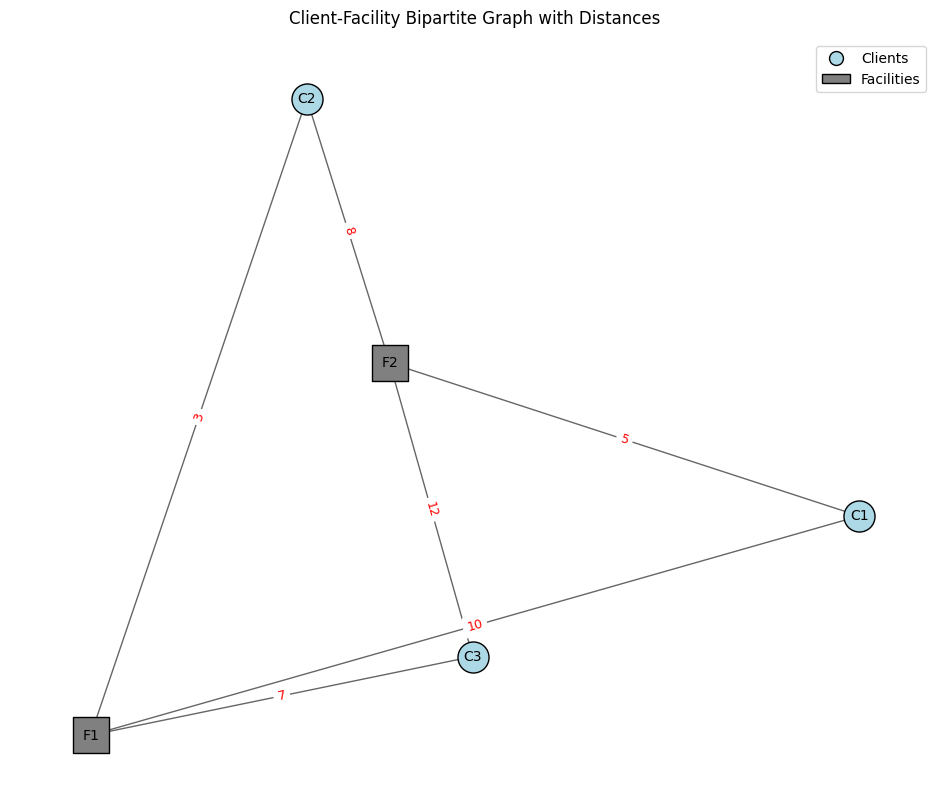

In [7]:
draw_initial_opmpum_graph(G)

## 2. Gurobi Model creation
Given the unified model (for dispersing facilities from clients) formulation

$$
\begin{align}
\max \quad & Kt - \sum_{i \in I} u_i \\
\text{s.t.} \quad & t - u_i \leq q_i, \quad \forall i \in I \\
& q_i = Ls_i - \sum_{j \in J} z(i,j), \quad \forall i \in I \\
& s_i - z(i,j) \leq d(i,j) + M(1-y_i), \quad \forall i \in I, j \in J \\
& \sum_{j \in J} y_j = p, \\
& u_i, z(i,j) \geq 0, y_j \in {0,1}, \forall i \in I, j \in J
\end{align}
$$

I create the following model

In [8]:
opmpum = gp.Model("Obnoxious_p_Median_Unified_Model")

Set parameter Username
Set parameter LicenseID to value 2627737
Academic license - for non-commercial use only - expires 2026-02-25


## 3. Add Decision Variables
$$
\begin{align}
& t: \quad \text{auxiliary variable} \\
\end{align}

In [9]:
t = opmpum.addVar(name="t", vtype=GRB.CONTINUOUS)

$$
\begin{align}
u_i &: \text{auxiliary variable for each client } i \\
u_i &= \begin{cases} 
\text{non-zero} & \text{if facility } i \text{ is associated with one of the } K \text{ smallest partial sums} \\
0 & \text{otherwise}
\end{cases}
\end{align}

In [10]:
u = opmpum.addVars(I, name="u", vtype=GRB.CONTINUOUS, lb=0.0)

$$
\begin{align}
& q_i: \quad \text{intermediate variable for each client } i \\
\end{align}

In [11]:
q = opmpum.addVars(I, name="q", vtype=GRB.CONTINUOUS)

$$
\begin{align}
& s_i: \quad \text{plays a role similar to } t \\
\end{align}

In [12]:
s = opmpum.addVars(I, name="s", vtype=GRB.CONTINUOUS)

$$
\begin{align}
z(i,j) &: \text{auxiliary variable} \\
z(i,j) &= \begin{cases} 
\text{non-zero} & \text{when facility } j \text{ is involved in the L closest facilities to client } i \\
0 & \text{otherwise}
\end{cases}
\end{align}

In [13]:
z = opmpum.addVars(I, J, name="z", vtype=GRB.CONTINUOUS, lb=0.0)

$$
\begin{align}
y_j &: \text{binary variable} \\
y_j &= \begin{cases} 
1 & \text{if facility } j \text{ is opened} \\
0 & \text{otherwise}
\end{cases}
\end{align}

In [14]:
y = opmpum.addVars(J, name="y", vtype=GRB.BINARY)

## 4. Set the Objective Function
$$
\begin{align}
\max \quad & Kt - \sum_{i \in I} u_i \\
\end{align}
$$

This objective aims to maximize the "dispersion" or "undesirability." $t$ is a variable that is pushed to be as large as possible, essentially representing the $K$-th smallest sum of distances from clients to opened facilities. Subtracting $u_i$ (which are minimized) further pushes the overall value up.

In [15]:
opmpum.setObjective(K * t - gp.quicksum(u[i] for i in I), GRB.MAXIMIZE)

## 5. Add Constraints
I now add all the constraints of the model

### Objective Linkage Constraint
$$
t - u_i \leq q_i, \quad \forall i \in I
$$

In [16]:
opmpum.addConstrs((t - u[i] <= q[i] for i in I), name="objective_linkage_constraint")
opmpum.update()

### $L$-th Smallest Distance Definition Constraint
$$
q_i = Ls_i - \sum_{j \in J} z(i,j), \quad \forall i \in I
$$

In [17]:
opmpum.addConstrs((q[i] == L * s[i] - gp.quicksum(z[i, j] for j in J) for i in I), name="l_th_smallest_distance_definition_constraint")
opmpum.update()

### Facility-Client Assignment Logic (Big M) Constraint
$$
s_i - z(i,j) \leq d(i,j) + M(1-y_i), \quad \forall i \in I, j \in J
$$

In [18]:
opmpum.addConstrs((s[i] - z[i, j] <= d[i, j] + M * (1 - y[j]) for i in I for j in J), name="facility_client_assignment_logic_constraint")
opmpum.update()

### Cardinality Constraint
$$
\sum_{j \in J} y_j = p
$$

In [19]:
opmpum.addConstr(gp.quicksum(y[j] for j in J) == p, name="cardinality_constraint")
opmpum.update()

## 6. Optimize the Model

In [20]:
opmpum.setParam("TimeLimit", 60) # Set a 60 seconds time limit
opmpum.update()
opmpum.write("opmpum.lp")
opmpum.optimize()

Set parameter TimeLimit to value 60
Gurobi Optimizer version 12.0.2 build v12.0.2rc0 (win64 - Windows 11.0 (22631.2))

CPU model: AMD A6-9225 RADEON R4, 5 COMPUTE CORES 2C+3G, instruction set [SSE2|AVX|AVX2]
Thread count: 2 physical cores, 2 logical processors, using up to 2 threads

Non-default parameters:
TimeLimit  60

Optimize a model with 13 rows, 18 columns and 41 nonzeros
Model fingerprint: 0xe2a4eba1
Variable types: 16 continuous, 2 integer (2 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+02]
  Objective range  [1e+00, 3e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+02]
Found heuristic solution: objective -0.0000000
Presolve removed 13 rows and 18 columns
Presolve time: 0.01s
Presolve: All rows and columns removed

Explored 0 nodes (0 simplex iterations) in 0.04 seconds (0.00 work units)
Thread count was 1 (of 2 available processors)

Solution count 2: 25 -0 

Optimal solution found (tolerance 1.00e-04)
Best objective 2.500000000000e+01, b

## 7. Print Results (if a solution is found)

I now create a function to print the results of the model

In [21]:
def print_model_solution(model, I, J, t, u, q, s, z, y):
    if model.status == GRB.OPTIMAL:
        print("\n--- Optimal Solution Found ---")
        print(f"Objective value: {model.objVal:.2f}")
        print(f"Variable t: {t.X:.2f}")

        print("\n--- Opened Facilities ---")
        for j in J:
            if y[j].X > 0.5: # Using > 0.5 for binary variables
                print(f"  Facility {j} is opened (y[{j}] = {int(y[j].X)})")

        print("\n--- Auxiliary Variables u_i ---")
        for i in I:
            print(f"  u[{i}]: {u[i].X:.2f}")
        
        print("\n--- Auxiliary Variables q ---")
        for i in I:
            print(f"  q[{i}]: {q[i].X:.2f}")

        print("\n--- Auxiliary Variables s_i ---")
        for i in I:
            print(f"  s[{i}]: {s[i].X:.2f}")
        
        print("\n--- Auxiliary Variables z_(i,j) ---")
        for i in I:
            for j in J:
                print(f"  z({i},{j}): {z[(i,j)].X:.2f}")

    else:
        print(f"\nModel did not solve to optimality. Status: {model.status}")

and immediately use it to print the optimal solution found

In [22]:
print_model_solution(opmpum, I, J, t, u, q, s, z, y)


--- Optimal Solution Found ---
Objective value: 25.00
Variable t: 12.00

--- Opened Facilities ---
  Facility 2 is opened (y[2] = 1)

--- Auxiliary Variables u_i ---
  u[1]: 7.00
  u[2]: 4.00
  u[3]: 0.00

--- Auxiliary Variables q ---
  q[1]: 5.00
  q[2]: 8.00
  q[3]: 12.00

--- Auxiliary Variables s_i ---
  s[1]: 5.00
  s[2]: 8.00
  s[3]: 12.00

--- Auxiliary Variables z_(i,j) ---
  z(1,1): 0.00
  z(1,2): 0.00
  z(2,1): 0.00
  z(2,2): 0.00
  z(3,1): 0.00
  z(3,2): 0.00


I also define a function that plot the solution graph

In [23]:
def plot_opmpum_solution(G, J, y):

    # Copy graph to avoid modifying original
    H = G.copy()

    # Get open facilities from the Gurobi model
    opened_facilities = [f"F{j}" for j in J if y[j].X > 0.5]
    
    # Identify all facilities
    all_facilities = [n for n, attr in H.nodes(data=True) if attr.get('type') == 'facility']
    
    # Facilities to remove = all except opened
    facilities_to_remove = set(all_facilities) - set(opened_facilities)
    
    # Remove facilities to remove from graph (this also removes their edges)
    H.remove_nodes_from(facilities_to_remove)
    
    # Now call the original plotting function on filtered graph
    draw_initial_opmpum_graph(H)


and then I plot the solution

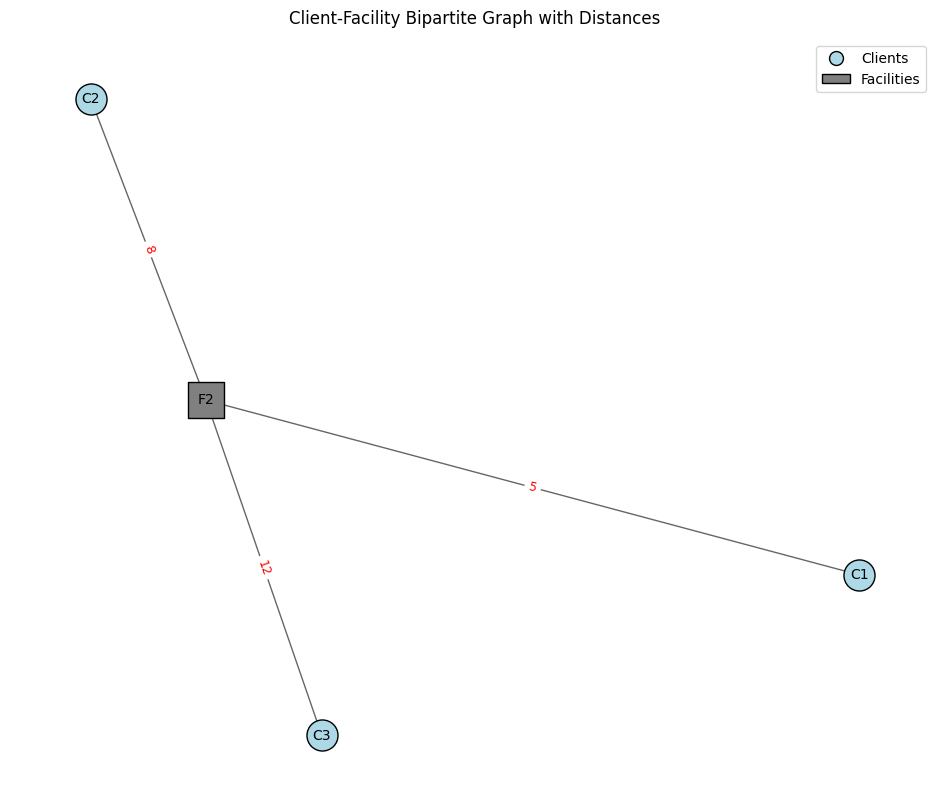

In [24]:
plot_opmpum_solution(G, J, y)

## 8. Test correctness
To test my toy model and ensure correctness, I define a brute-force algorithm 

In [25]:
from itertools import combinations

def brute_force_opmpum(I, J, d, p):
    best_facility_set = None
    best_total_min_distance = -float("inf")
    best_assignment = {}

    # Generate all combinations of p facilities
    for facility_set in combinations(J, p):
        total_min_distance = 0
        assignment = {}

        for i in I:
            # Find nearest facility in the current facility set
            min_dist = float("inf")
            for j in facility_set:
                if d[(i, j)] < min_dist:
                    min_dist = d[(i, j)]
                    assignment[i] = j
            total_min_distance += min_dist

        if total_min_distance > best_total_min_distance:
            best_total_min_distance = total_min_distance
            best_facility_set = facility_set
            best_assignment = assignment.copy()

    return best_facility_set, best_total_min_distance, best_assignment

that I run with the data

In [26]:
best_facilities, best_obj, assignment = brute_force_opmpum(I, J, d, p)

print("Best facility set (y_j = 1):", best_facilities)
print("Maximum total minimum distance (objective):", best_obj)
print("Client assignments:")
for i in I:
    print(f"  Client {i} → Facility {assignment[i]}")

Best facility set (y_j = 1): (2,)
Maximum total minimum distance (objective): 25
Client assignments:
  Client 1 → Facility 2
  Client 2 → Facility 2
  Client 3 → Facility 2


Now, I define an helper function to automatically compare the Gurobi solution and the brute-force result

In [27]:
def validate_opmp_unified_model(best_facilities, best_obj, assignment, gurobi_model, t, u, s, q, z, y, I, J, d, p, L, M):

    if gurobi_model.status != GRB.OPTIMAL:
        print("Gurobi did not find an optimal solution.")
        return

    gurobi_obj = gurobi_model.objVal
    gurobi_open_facilities = [j for j in J if y[j].X > 0.5]
    gurobi_open_set = tuple(sorted(gurobi_open_facilities))

    print(f"\nGurobi Objective: {gurobi_obj:.2f}")
    print(f"Brute-force Objective: {best_obj:.2f}")
    print(f"Facilities from Gurobi: {gurobi_open_set}")
    print(f"Facilities from Brute-Force: {best_facilities}")

    # Objective match check
    if abs(gurobi_obj - best_obj) > 1e-6:
        print("Objective mismatch!")
    else:
        print("Objective matches")

    # Facility selection check
    if set(gurobi_open_facilities) != set(best_facilities):
        print("Facility set differs (but may be optimal tie)")
    else:
        print("Facility set matches")

    # Cardinality constraint
    total_y = sum(int(y[j].X + 0.5) for j in J)
    if total_y != p:
        print(f"Cardinality constraint violated: ∑y = {total_y} ≠ {p}")
    else:
        print("Cardinality constraint ∑y = p is satisfied")

    tolerance = 1e-6
    failed = False

    for i in I:
        # Constraint: t - u_i ≤ q_i
        if t.X - u[i].X > q[i].X + tolerance:
            print(f"Constraint violated: t - u[{i}] > q[{i}]")
            failed = True

        # Constraint: q_i = L·s_i - ∑ z(i,j)
        z_sum = sum(z[i, j].X for j in J)
        lhs = q[i].X
        rhs = L * s[i].X - z_sum
        if abs(lhs - rhs) > tolerance:
            print(f"Constraint violated: q[{i}] ≠ L·s[{i}] - ∑z({i},j)")
            failed = True

        for j in J:
            # Constraint: s_i - z(i,j) ≤ d(i,j) + M(1 - y_j)
            left = s[i].X - z[i, j].X
            right = d[(i, j)] + M * (1 - y[j].X)
            if left > right + tolerance:
                print(f"Constraint violated: s[{i}] - z[{i},{j}] > d + M(1 - y)")
                failed = True

    if not failed:
        print("All constraints passed.")

    print("\nBrute-force Assignments:")
    for i in I:
        j = assignment[i]
        print(f"  Client {i} → Facility {j} (distance: {d[i, j]})")


an I call it to ensure correctness

In [28]:
validate_opmp_unified_model(
    best_facilities, best_obj, assignment, 
    opmpum, t, u, s, q, z, y,
    I=I, J=J, d=d, p=p, L=L, M=M
)


Gurobi Objective: 25.00
Brute-force Objective: 25.00
Facilities from Gurobi: (2,)
Facilities from Brute-Force: (2,)
Objective matches
Facility set matches
Cardinality constraint ∑y = p is satisfied
All constraints passed.

Brute-force Assignments:
  Client 1 → Facility 2 (distance: 5)
  Client 2 → Facility 2 (distance: 8)
  Client 3 → Facility 2 (distance: 12)


## 9. Paper dataset example
Let's now test the model with an instance given by the reference paper.
First thing first, I create a function to extract the .gz files

In [29]:
import gzip

def read_gz_file(file_path, encoding='utf-8'):
    try:
        with gzip.open(file_path, 'rt', encoding=encoding) as f:
            content = f.read()
        return content
    except FileNotFoundError:
        print(f"Error: The file '{file_path}' was not found.")
        return None
    except Exception as e:
        print(f"An error occurred while reading the file: {e}")
        return None

In [30]:
file_content = read_gz_file('obnoxious-p-median-master/data/orlib-cap41.gz')

In [31]:
file_content

'type=table\nn=50\nm=16\np=4\n\nclients = {c0, c1, c2, c3, c4, c5, c6, c7, c8, c9, c10, c11, c12, c13, c14, c15, c16, c17, c18, c19, \nc20, c21, c22, c23, c24, c25, c26, c27, c28, c29, c30, c31, c32, c33, c34, c35, c36, c37, c38, c39, \nc40, c41, c42, c43, c44, c45, c46, c47, c48, c49}\n\nfacilities = {f0, f1, f2, f3, f4, f5, f6, f7, f8, f9, f10, f11, f12, f13, f14, f15}\n\ntable = {\n{6739.72500,10355.05000,7650.40000,5219.50000,5776.12500,6641.17500,4374.52500,3847.10000,6429.47500,5396.52500,5219.50000,4182.90000,7391.25000,5038.82500,10349.57500,6051.7},\n{3204.86250,5457.07500,3845.40000,2396.85000,2628.48750,3220.08750,1838.96250,2266.35000,3117.86250,2582.81250,2296.80000,1779.15000,5115.60000,2189.13750,5399.43750,2838.4},\n{4914.00000,26409.60000,19622.40000,13876.80000,9147.60000,14977.20000,21848.40000,35330.40000,15111.60000,23679.60000,9828.00000,19303.20000,57472.80000,11180.40000,22957.20000,15489.6},\n{32372.11250,29982.22500,21024.32500,29681.40000,21275.01250,20071.71

Now I make another function to parse the content of the file

In [32]:
import re

def parse_obnoxious_data(file_content_string):

    data = {}

    # Extract n, m, p
    n_match = re.search(r'n=(\d+)', file_content_string)
    m_match = re.search(r'm=(\d+)', file_content_string)
    p_match = re.search(r'p=(\d+)', file_content_string)

    if n_match and m_match and p_match:
        data['n'] = int(n_match.group(1))
        data['m'] = int(m_match.group(1))
        data['p'] = int(p_match.group(1))
    else:
        print("Error: Could not find n, m, or p parameters.")
        return None

    # Extract clients
    clients_match = re.search(r'clients = \{(.*?)\}', file_content_string, re.DOTALL)
    if clients_match:
        clients_str = clients_match.group(1).replace('\n', '').replace(' ', '')
        data['clients'] = clients_str.split(',')
    else:
        print("Error: Could not find clients set.")
        return None

    # Extract facilities
    facilities_match = re.search(r'facilities = \{(.*?)\}', file_content_string, re.DOTALL)
    if facilities_match:
        facilities_str = facilities_match.group(1).replace('\n', '').replace(' ', '')
        data['facilities'] = facilities_str.split(',')
    else:
        print("Error: Could not find facilities set.")
        return None

    # Extract table (distances)
    # This regex captures everything from '{' after 'table =' until the final '}' for the table block,
    # being more lenient with internal whitespace and newlines.
    table_match = re.search(r'table = \{\s*((?:.|\s)*?)\s*\}\s*$', file_content_string, re.DOTALL)
    if table_match:
        table_content = table_match.group(1)
        # Remove all whitespace (including newlines) to simplify splitting, then strip leading/trailing braces
        rows_raw = table_content.strip().split('},')
        distance_table = []
        for row_str in rows_raw:
            clean_row_str = row_str.strip(' \n{}') # Clean up any remaining braces or whitespace
            if clean_row_str:
                # Convert each string number to float
                distance_table.append([float(val) for val in clean_row_str.split(',')])
            else:
                # Handle cases where a split might result in an empty string
                continue # Skip empty rows if any
        data['table'] = distance_table
    else:
        print("Error: Could not find table data with the improved regex.")
        return None

    return data

In [33]:
parsed_data = parse_obnoxious_data(file_content)

In [34]:
parsed_data

{'n': 50,
 'm': 16,
 'p': 4,
 'clients': ['c0',
  'c1',
  'c2',
  'c3',
  'c4',
  'c5',
  'c6',
  'c7',
  'c8',
  'c9',
  'c10',
  'c11',
  'c12',
  'c13',
  'c14',
  'c15',
  'c16',
  'c17',
  'c18',
  'c19',
  'c20',
  'c21',
  'c22',
  'c23',
  'c24',
  'c25',
  'c26',
  'c27',
  'c28',
  'c29',
  'c30',
  'c31',
  'c32',
  'c33',
  'c34',
  'c35',
  'c36',
  'c37',
  'c38',
  'c39',
  'c40',
  'c41',
  'c42',
  'c43',
  'c44',
  'c45',
  'c46',
  'c47',
  'c48',
  'c49'],
 'facilities': ['f0',
  'f1',
  'f2',
  'f3',
  'f4',
  'f5',
  'f6',
  'f7',
  'f8',
  'f9',
  'f10',
  'f11',
  'f12',
  'f13',
  'f14',
  'f15'],
 'table': [[6739.725,
   10355.05,
   7650.4,
   5219.5,
   5776.125,
   6641.175,
   4374.525,
   3847.1,
   6429.475,
   5396.525,
   5219.5,
   4182.9,
   7391.25,
   5038.825,
   10349.575,
   6051.7],
  [3204.8625,
   5457.075,
   3845.4,
   2396.85,
   2628.4875,
   3220.0875,
   1838.9625,
   2266.35,
   3117.8625,
   2582.8125,
   2296.8,
   1779.15,
   5115.6

Now I convert the parsed file structure table in a way that I can use with my previous functions

In [35]:
def convert_parsed_file(parsed_file_data):
    d = {}
    for i in range(len(parsed_file_data['clients'])): # iterate clients
        for j in range(len(parsed_file_data['facilities'])): # iterate facilities
            d[(i+1,j+1)] = parsed_file_data['table'][i][j]
    new_data_structure = {
        'n': parsed_file_data['n'],
        'm': parsed_file_data['m'],
        'p': parsed_file_data['p'],
        'I': [i+1 for i in range(len(parsed_file_data['clients']))],
        'J': [j+1 for j in range(len(parsed_file_data['facilities']))],
        'd': d,
    }
    return new_data_structure

In [36]:
new_data_structure = convert_parsed_file(parsed_data)

In [37]:
new_data_structure

{'n': 50,
 'm': 16,
 'p': 4,
 'I': [1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40,
  41,
  42,
  43,
  44,
  45,
  46,
  47,
  48,
  49,
  50],
 'J': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16],
 'd': {(1, 1): 6739.725,
  (1, 2): 10355.05,
  (1, 3): 7650.4,
  (1, 4): 5219.5,
  (1, 5): 5776.125,
  (1, 6): 6641.175,
  (1, 7): 4374.525,
  (1, 8): 3847.1,
  (1, 9): 6429.475,
  (1, 10): 5396.525,
  (1, 11): 5219.5,
  (1, 12): 4182.9,
  (1, 13): 7391.25,
  (1, 14): 5038.825,
  (1, 15): 10349.575,
  (1, 16): 6051.7,
  (2, 1): 3204.8625,
  (2, 2): 5457.075,
  (2, 3): 3845.4,
  (2, 4): 2396.85,
  (2, 5): 2628.4875,
  (2, 6): 3220.0875,
  (2, 7): 1838.9625,
  (2, 8): 2266.35,
  (2, 9): 3117.8625,
  (2, 10): 2582.8125,
  (2, 11): 2296.8,
  (2, 12): 1779.15,
  (2, 13): 5115.6,
  (2, 14): 2189.1375,
  (2, 15

Now I build the graph in order to show it

In [38]:
G = build_bipartite_graph(new_data_structure['n'], new_data_structure['m'], new_data_structure['d'])

In [39]:
G.nodes.data()

NodeDataView({'C1': {'type': 'client', 'pos': (91.23, 62.92)}, 'C2': {'type': 'client', 'pos': (61.27, 13.86)}, 'C3': {'type': 'client', 'pos': (24.65, 73.22)}, 'C4': {'type': 'client', 'pos': (19.5, 15.67)}, 'C5': {'type': 'client', 'pos': (84.69, 43.0)}, 'C6': {'type': 'client', 'pos': (17.05, 58.35)}, 'C7': {'type': 'client', 'pos': (6.27, 98.39)}, 'C8': {'type': 'client', 'pos': (24.99, 15.19)}, 'C9': {'type': 'client', 'pos': (24.54, 1.34)}, 'C10': {'type': 'client', 'pos': (91.21, 72.92)}, 'C11': {'type': 'client', 'pos': (75.97, 63.42)}, 'C12': {'type': 'client', 'pos': (36.9, 3.69)}, 'C13': {'type': 'client', 'pos': (38.75, 91.76)}, 'C14': {'type': 'client', 'pos': (10.05, 71.06)}, 'C15': {'type': 'client', 'pos': (54.27, 70.14)}, 'C16': {'type': 'client', 'pos': (30.29, 66.56)}, 'C17': {'type': 'client', 'pos': (91.3, 40.88)}, 'C18': {'type': 'client', 'pos': (23.9, 27.38)}, 'C19': {'type': 'client', 'pos': (5.54, 80.12)}, 'C20': {'type': 'client', 'pos': (65.24, 44.41)}, 'C21

In [40]:
G.edges.data()

EdgeDataView([('C1', 'F1', {'cost': 6739.725}), ('C1', 'F2', {'cost': 10355.05}), ('C1', 'F3', {'cost': 7650.4}), ('C1', 'F4', {'cost': 5219.5}), ('C1', 'F5', {'cost': 5776.125}), ('C1', 'F6', {'cost': 6641.175}), ('C1', 'F7', {'cost': 4374.525}), ('C1', 'F8', {'cost': 3847.1}), ('C1', 'F9', {'cost': 6429.475}), ('C1', 'F10', {'cost': 5396.525}), ('C1', 'F11', {'cost': 5219.5}), ('C1', 'F12', {'cost': 4182.9}), ('C1', 'F13', {'cost': 7391.25}), ('C1', 'F14', {'cost': 5038.825}), ('C1', 'F15', {'cost': 10349.575}), ('C1', 'F16', {'cost': 6051.7}), ('C2', 'F1', {'cost': 3204.8625}), ('C2', 'F2', {'cost': 5457.075}), ('C2', 'F3', {'cost': 3845.4}), ('C2', 'F4', {'cost': 2396.85}), ('C2', 'F5', {'cost': 2628.4875}), ('C2', 'F6', {'cost': 3220.0875}), ('C2', 'F7', {'cost': 1838.9625}), ('C2', 'F8', {'cost': 2266.35}), ('C2', 'F9', {'cost': 3117.8625}), ('C2', 'F10', {'cost': 2582.8125}), ('C2', 'F11', {'cost': 2296.8}), ('C2', 'F12', {'cost': 1779.15}), ('C2', 'F13', {'cost': 5115.6}), ('C2

and then I call the function to plot it

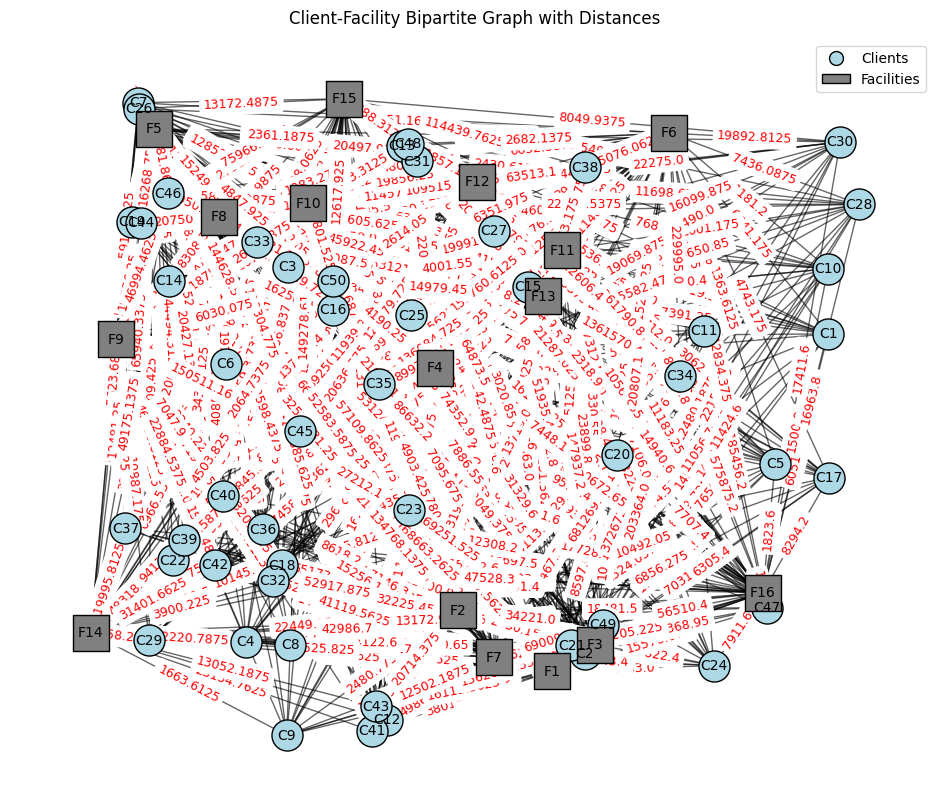

In [41]:
draw_initial_opmpum_graph(G)

Because Gurobi models are not dynamic in the sense that I can just change the data (I, J, d, etc.) and reuse the same model object, to test different instances of the Gurobi model without rewriting the entire model definition, I encapsulate the model building and optimization logic into a function

In [42]:
def build_and_optimize_opmpum_model(I, J, d, p, M, K=None, L=None, time_limit=60):

    # If we need the unified model to act exactly like the OpMP model
    if(K == None):
        K = len(I)
    
    # If we need the unified model to act exactly like the OpMP model
    if(L == None):
        L = 1

    # Create a new model instance for each call
    opmpum = gp.Model("Obnoxious_p_Median_Unified_Model")

    # Define variables
    t = opmpum.addVar(name="t", vtype=GRB.CONTINUOUS)
    u = opmpum.addVars(I, name="u", vtype=GRB.CONTINUOUS, lb=0.0)
    q = opmpum.addVars(I, name="q", vtype=GRB.CONTINUOUS)
    s = opmpum.addVars(I, name="s", vtype=GRB.CONTINUOUS)
    z = opmpum.addVars(I, J, name="z", vtype=GRB.CONTINUOUS, lb=0.0)
    y = opmpum.addVars(J, name="y", vtype=GRB.BINARY)

    # Set objective function
    opmpum.setObjective(K * t - gp.quicksum(u[i] for i in I), GRB.MAXIMIZE)

    # Add constraints
    opmpum.addConstrs((t - u[i] <= q[i] for i in I), name="objective_linkage_constraint")
    opmpum.update()
    opmpum.addConstrs((q[i] == L * s[i] - gp.quicksum(z[i, j] for j in J) for i in I), name="l_th_smallest_distance_definition_constraint")
    opmpum.update()
    opmpum.addConstrs((s[i] - z[i, j] <= d[i, j] + M * (1 - y[j]) for i in I for j in J), name="facility_client_assignment_logic_constraint")
    opmpum.update()
    opmpum.addConstr(gp.quicksum(y[j] for j in J) == p, name="cardinality_constraint")
    opmpum.update()

    # Set parameters
    opmpum.setParam("TimeLimit", time_limit)
    opmpum.update()

    # Write to file
    opmpum.write("opmpum.lp")
    
    # Optimize the model
    opmpum.optimize()

    return opmpum, t, u, q, s, z, y

Before calling this function, I need to define M. Becuase M should be greater than or equal to the maximum possible distance d(i,j), I create a function that finds the maximum possibile distance and returns it incremented by a custom value like, for example, 100.

In [43]:
def compute_M(d, padding=100):
    if not d:
        return None  # Handle empty dictionary case
    return max(d.values()) + padding

and I immediately call it

In [44]:
new_data_structure['M'] = compute_M(new_data_structure['d'])

In [45]:
new_data_structure['M']

1361670.4

Now I have all the ingredients to finally test the problem given by the paper with the values of the dataset (always given by the paper). For example, with $p=2$

In [46]:
# Set of clients I
I = new_data_structure['I']
n = len(I)

# Set of potential facility sites J
J = new_data_structure['J']
m = len(J)

# Number of facilities to open (Constraint (5))
p = 2

# Distance d(i,j) between client i and facility j
d = new_data_structure['d']

# A large enough positive number M
M = new_data_structure['M']

In [47]:
opmpum, t, u, q, s, z, y = build_and_optimize_opmpum_model(I, J, d, p, M)

Set parameter TimeLimit to value 60
Gurobi Optimizer version 12.0.2 build v12.0.2rc0 (win64 - Windows 11.0 (22631.2))

CPU model: AMD A6-9225 RADEON R4, 5 COMPUTE CORES 2C+3G, instruction set [SSE2|AVX|AVX2]
Thread count: 2 physical cores, 2 logical processors, using up to 2 threads

Non-default parameters:
TimeLimit  60

Optimize a model with 901 rows, 967 columns and 3466 nonzeros
Model fingerprint: 0xe33cef51
Variable types: 951 continuous, 16 integer (16 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+06]
  Objective range  [1e+00, 5e+01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [2e+00, 3e+06]
Found heuristic solution: objective -0.0000000
Presolve removed 50 rows and 850 columns
Presolve time: 0.09s
Presolved: 851 rows, 117 columns, 2516 nonzeros
Variable types: 101 continuous, 16 integer (16 binary)

Root relaxation: objective 6.041105e+07, 197 iterations, 0.03 seconds (0.01 work units)

    Nodes    |    Current Node    |     Objective Bounds      |    

I then print the data

In [48]:
print_model_solution(opmpum, I, J, t, u, q, s, z, y)


--- Optimal Solution Found ---
Objective value: 2871881.85
Variable t: 810550.80

--- Opened Facilities ---
  Facility 8 is opened (y[8] = 1)
  Facility 13 is opened (y[13] = 1)

--- Auxiliary Variables u_i ---
  u[1]: 806703.70
  u[2]: 808284.45
  u[3]: 775220.40
  u[4]: 730364.23
  u[5]: 809595.23
  u[6]: 783299.55
  u[7]: 655256.55
  u[8]: 752643.23
  u[9]: 809338.88
  u[10]: 810004.40
  u[11]: 590338.68
  u[12]: 769215.40
  u[13]: 739339.85
  u[14]: 802242.50
  u[15]: 788841.30
  u[16]: 802415.10
  u[17]: 803431.80
  u[18]: 669175.80
  u[19]: 800335.93
  u[20]: 804179.18
  u[21]: 808931.05
  u[22]: 776737.50
  u[23]: 786706.28
  u[24]: 792402.00
  u[25]: 785866.25
  u[26]: 793439.62
  u[27]: 686499.60
  u[28]: 785090.68
  u[29]: 790101.95
  u[30]: 776470.05
  u[31]: 798665.85
  u[32]: 795940.05
  u[33]: 777705.05
  u[34]: 0.00
  u[35]: 799858.30
  u[36]: 800348.55
  u[37]: 588547.07
  u[38]: 695972.73
  u[39]: 776199.68
  u[40]: 790788.80
  u[41]: 747891.53
  u[42]: 769696.53
  u[

Finally, I also plot the solution

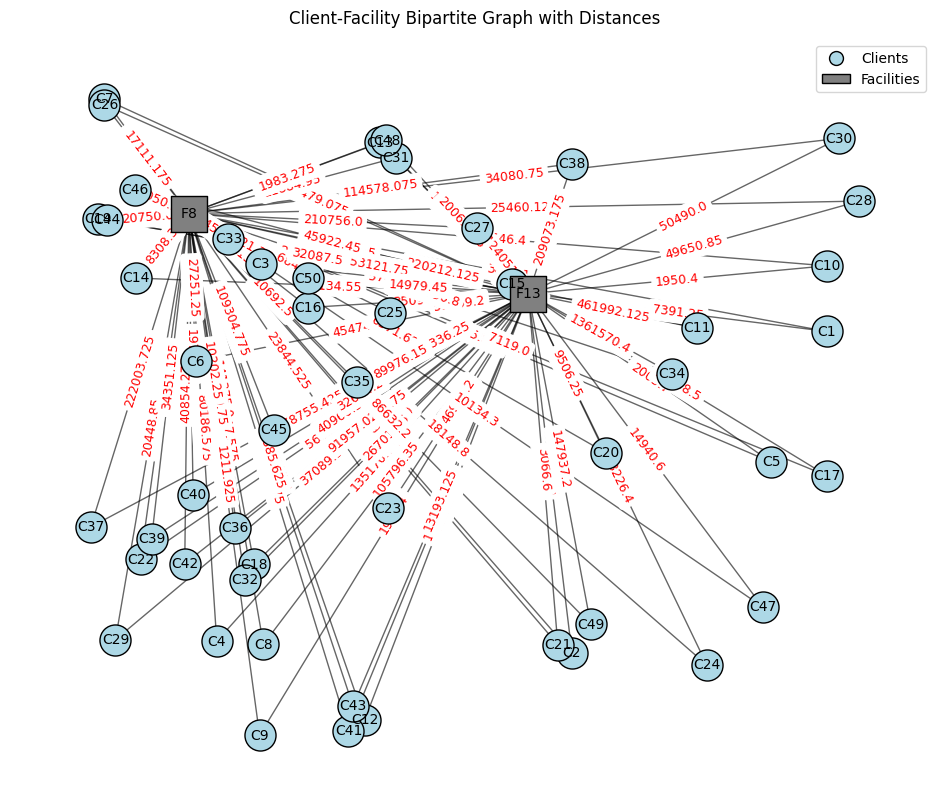

In [49]:
plot_opmpum_solution(G, J, y)